# BÀI TẬP LỚN: DỰ BÁO TRỄ CHUYẾN BAY THƯƠNG MẠI TỪ DỮ LIỆU THỰC TẾ (NYC 2013)
### Môn học: Nhập môn Khoa học Dữ liệu (IT4930 / IT4142) - SoICT, Đại học Bách Khoa Hà Nội (HUST)
---
Notebook chạy lại toàn bộ pipeline trong `src/` và hiển thị kết quả. Mọi con số in ra dưới đây được tính khi chạy, không gõ tay.

1. **Giai đoạn A** - Thu thập 3 nguồn dữ liệu (chuyến bay nycflights13, thời tiết ASOS, Web Crawler Wikipedia/FAA) và tích hợp qua Mediated Schema
2. **Giai đoạn B** - Làm sạch (median chỉ tính trên Train), thống kê mô tả đơn biến
3. **Giai đoạn C** - Kỹ nghệ đặc trưng (K-Means/one-hot chỉ fit trên Train) và 11 biểu đồ EDA
4. **Giai đoạn D** - Huấn luyện, chọn siêu tham số trên Validation, đánh giá 1 lần trên Test
5. **Kết luận và giới hạn**

In [1]:
import os, sys
# Chạy notebook từ thư mục notebooks/ hoặc thư mục gốc đều được
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())
import pandas as pd
from IPython.display import display, Image
pd.set_option('display.width', 200)
print('Thư mục làm việc:', os.getcwd())

Thư mục làm việc: D:\IT4930_PROJECT\NMKHDL


## 1. Giai đoạn A: Thu thập & Tích hợp Dữ liệu Đa nguồn
- **Nguồn 1 - Chuyến bay:** bảng `flights` của gói nycflights13 (Wickham; trích từ US BTS), 336.776 chuyến khởi hành từ JFK/EWR/LGA năm 2013; lấy mẫu đều 50.000 chuyến theo thời gian.
- **Nguồn 2 - Thời tiết:** bảng `weather` của nycflights13 (trạm ASOS/NOAA theo giờ, đủ 3 sân bay), tải qua HTTP từ Rdatasets.
- **Nguồn 3 - Web Crawler:** cào bảng *List of the busiest airports in the United States* (Wikipedia, số liệu FAA) bằng `requests` + `BeautifulSoup`.
- Tích hợp: thời tiết ghép theo khóa `(origin, year, month, day, hour)`, quy mô sân bay đến ghép theo `dest` (mã IATA).

In [2]:
from src.data_collection.fetch_flights import load_real_flights_stream
from src.data_collection.fetch_weather_api import download_weather_raw, load_real_weather_stream
from src.data_collection.web_crawler import AirportTrafficCrawler
from src.data_integration.integrate import DataIntegrationEngine

flights = load_real_flights_stream()
if not os.path.exists('data/raw/nyc_weather_raw.csv'):
    download_weather_raw()
weather = load_real_weather_stream()
print('Số quan trắc thời tiết theo sân bay:', weather['origin'].value_counts().to_dict())

# Dùng bản HTML đã lưu nếu có (chạy lại không cần mạng); xóa file để cào lại từ web
crawler = AirportTrafficCrawler()
traffic = crawler.crawl_airport_traffic(use_cache=os.path.exists(crawler.html_path))
display(traffic[['iata', 'airport_name', 'hub_category', 'enplanements_2016', 'enplanements_2025']].head())

df_integrated = DataIntegrationEngine().integrate()
df_integrated.head()

[Task A1] Đang nạp và chuẩn hóa dữ liệu chuyến bay thực tế từ: data/raw/nyc_flights_raw.csv...


[Task A1 - Hoàn tất] Đã lưu 50000 chuyến bay THẬT vào: data/raw/flights_stream.csv
[Task A2] Đang nạp và chuẩn hóa dữ liệu khí tượng NOAA từ: data/raw/nyc_weather_raw.csv...
[Task A2] Phát hiện 1 giá trị gió phi vật lý (> 200 km/h) -> đặt NaN


[Task A2 - Hoàn tất] Đã lưu 26115 quan trắc khí tượng thật vào: data/raw/weather_stream.csv
Số quan trắc thời tiết theo sân bay: {'JFK': 8706, 'LGA': 8706, 'EWR': 8703}
[Web Crawler] Đọc trang đã lưu: data/raw\wiki_busiest_us_airports.html
[Web Crawler - Hoàn tất] Cào được 65 sân bay hub (30 large, 35 medium) -> data/raw\crawled_us_airport_traffic.csv


,iata,airport_name,hub_category,enplanements_2016,enplanements_2025
0,ATL,Hartsfield–Jackson Atlanta International Airport,Large hub,50501858,51459786
1,DFW,Dallas/Fort Worth International Airport,Large hub,31283579,41297009
2,ORD,O'Hare International Airport,Large hub,37589899,40680735
3,DEN,Denver International Airport,Large hub,28267394,39976695
4,LAX,Los Angeles International Airport,Large hub,39636042,36497303


[Task A3] Đang nạp và hợp nhất 2 nguồn dữ liệu THẬT qua Wrappers...
[Task A3] Đã ghép dữ liệu Web Crawler: 89.2% chuyến bay có sân bay đến là hub


[Task A3 - Hoàn thành] Đã hợp nhất thành công 50000 chuyến bay thật vào: data/processed/integrated_flight_weather.csv
Cấu trúc Mediated Schema: ['flight_id', 'airline', 'tailnum', 'origin', 'dest', 'dep_timestamp', 'year', 'month', 'day', 'hour', 'minute', 'air_time', 'distance', 'delay_minutes', 'delay_status', 'is_delayed_30', 'origin_temp_c', 'origin_rain_mm', 'origin_wind_kmh', 'origin_gusts_kmh', 'origin_visibility_km', 'humid', 'pressure', 'origin_weather', 'dest_hub_tier', 'dest_enplanements_m']


,flight_id,airline,tailnum,origin,dest,dep_timestamp,year,month,day,hour,...,origin_temp_c,origin_rain_mm,origin_wind_kmh,origin_gusts_kmh,origin_visibility_km,humid,pressure,origin_weather,dest_hub_tier,dest_enplanements_m
0,UA1545_20130101_00001,UA,N14228,EWR,IAH,2013-01-01 05:17:00,2013,1,1,5,...,3.9,0.0,20.4,20.4,16.1,64.43,1011.9,Quang đãng,2,20.062
1,B6507_20130101_00002,B6,N516JB,EWR,FLL,2013-01-01 05:55:00,2013,1,1,5,...,3.9,0.0,20.4,20.4,16.1,64.43,1011.9,Quang đãng,2,14.263
2,B649_20130101_00003,B6,N793JB,JFK,PBI,2013-01-01 05:58:00,2013,1,1,5,...,3.9,0.0,24.1,24.1,16.1,61.63,1012.1,Quang đãng,0,0.000
3,B6343_20130101_00004,B6,N644JB,EWR,PBI,2013-01-01 06:01:00,2013,1,1,6,...,3.3,0.0,18.5,18.5,16.1,67.21,1012.4,Quang đãng,0,0.000
4,UA303_20130101_00005,UA,N532UA,JFK,SFO,2013-01-01 06:11:00,2013,1,1,6,...,3.3,0.0,22.2,22.2,16.1,64.29,1012.6,Quang đãng,2,25.707


## 2. Giai đoạn B: Làm sạch Dữ liệu & Thống kê Mô tả Đơn biến
- Median điền khuyết theo (sân bay, tháng) **chỉ tính trên tập Train** (70% đầu theo thời gian).
- Loại `air_time` (thời gian bay thực tế, chỉ biết sau khi hạ cánh) để tránh rò rỉ thông tin tương lai.
- Thống kê mô tả biến mục tiêu `delay_minutes` (= `dep_delay`).

In [3]:
from src.preprocessing.cleaner import DataCleaner

cleaner = DataCleaner()
missing = cleaner.check_missing_values()
print('Các cột có giá trị khuyết TRƯỚC khi xử lý:')
display(missing[missing['Missing_Count'] > 0])

df_cleaned = cleaner.run_cleaning_pipeline()
print('Số ô khuyết SAU khi xử lý:', int(df_cleaned.isna().sum().sum()))
pd.DataFrame([cleaner.compute_univariate_statistics('delay_minutes')]).T

Các cột có giá trị khuyết TRƯỚC khi xử lý:


,Missing_Count,Missing_Ratio_%
air_time,199,0.40
origin_temp_c,241,0.48
origin_rain_mm,240,0.48
origin_wind_kmh,250,0.50
origin_gusts_kmh,250,0.50
origin_visibility_km,240,0.48
humid,241,0.48
pressure,5391,10.78
origin_weather,240,0.48


[Task B] Bắt đầu pipeline làm sạch và thống kê dữ liệu thật...


[Task B - Hoàn thành] Đã lưu dữ liệu làm sạch tại: data/processed/cleaned_flight_data.csv
Thống kê đơn biến thời gian trễ thực tế (delay_minutes):
  - Thuộc tính: delay_minutes
  - Số lượng mẫu (Count): 50000
  - Trung bình (Mean): 12.53
  - Trung vị (Median): -1.0
  - Yếu vị (Mode): -5.0
  - Phương sai (Variance): 1582.2
  - Độ lệch chuẩn (Std Dev): 39.78
  - Độ bất đối xứng (Skewness): 4.7275
  - Độ nhọn (Kurtosis): 41.0175
  - Trễ nhỏ nhất (Min): -30.0
  - Trễ lớn nhất (Max): 960.0
Số ô khuyết SAU khi xử lý: 0


,0
Thuộc tính,delay_minutes
Số lượng mẫu (Count),50000
Trung bình (Mean),12.53
Trung vị (Median),-1.0
Yếu vị (Mode),-5.0
Phương sai (Variance),1582.2
Độ lệch chuẩn (Std Dev),39.78
Độ bất đối xứng (Skewness),4.7275
Độ nhọn (Kurtosis),41.0175
Trễ nhỏ nhất (Min),-30.0


## 3. Giai đoạn C: Kỹ nghệ Đặc trưng & Trực quan hóa (EDA)
- Đặc trưng lịch (giờ, ngày, tháng, sin/cos), trễ trung bình của sân bay ở giờ t-1 và trung bình 3 giờ trước.
- Đặc trưng thời tiết và quy mô sân bay đến (từ Web Crawler).
- K-Means (k=3) trên (giờ, khoảng cách) đã chuẩn hóa - fit trên Train.

In [4]:
from src.preprocessing.feature_engineering import build_features
from src.visualization.eda_plots import generate_all_eda_plots

df_featured = build_features()
print('Đặc điểm 3 cụm K-Means:')
display(df_featured.groupby('flight_load_cluster').agg(so_chuyen=('hour', 'size'), gio_TB=('hour', 'mean'),
        khoang_cach_TB=('distance', 'mean'), tre_TB=('delay_minutes', 'mean')).round(1))

generate_all_eda_plots()
figs = sorted(f for f in os.listdir('docs/figures') if f.startswith('task_c') and f.endswith('.png'))
print(f'Đã sinh {len(figs)} biểu đồ EDA:', figs)

[Task C] Bắt đầu quá trình kỹ nghệ đặc trưng trên dữ liệu THẬT...


[Task C] Đã fit K-Means (k=3) trên tập Train và lưu tại: models_saved


[Task C - Hoàn thành] Đã tạo thành công 67 cột cho 50000 chuyến bay THẬT vào: data/processed/featured_flight_dataset.csv
Đặc điểm 3 cụm K-Means:


,so_chuyen,gio_TB,khoang_cach_TB,tre_TB
flight_load_cluster,,,,
0,18603,8.4,784.7,3.9
1,8976,13.4,2380.6,10.0
2,22421,17.0,740.9,20.7


[Task C] Bắt đầu sinh toàn bộ các biểu đồ EDA...


D:\IT4930_PROJECT\NMKHDL\src\visualization\eda_plots.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='airline', y='delay_minutes', data=df_top, palette='Set2', ax=axes[0], showfliers=False)
D:\IT4930_PROJECT\NMKHDL\src\visualization\eda_plots.py:193: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='origin', y='delay_minutes', data=df, palette='Pastel1', ax=axes[1], showfliers=False)


D:\IT4930_PROJECT\NMKHDL\src\visualization\eda_plots.py:211: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='airline', y='delay_capped', data=df_top, palette='muted', inner='quartile', ax=ax)


[Task C - Hoàn tất] Toàn bộ các đồ thị EDA đã được lưu tại: docs/figures
Đã sinh 11 biểu đồ EDA: ['task_c10_pca_analysis.png', 'task_c11_kmeans_elbow.png', 'task_c1_run_sequence.png', 'task_c2_lag_plot.png', 'task_c3_heatmap_24x7.png', 'task_c4_correlation_heatmap.png', 'task_c5_parallel_coordinates.png', 'task_c6_monthly_hub_delay.png', 'task_c7_delay_histogram.png', 'task_c8_boxplot_airline_airport.png', 'task_c9_violin_plot.png']


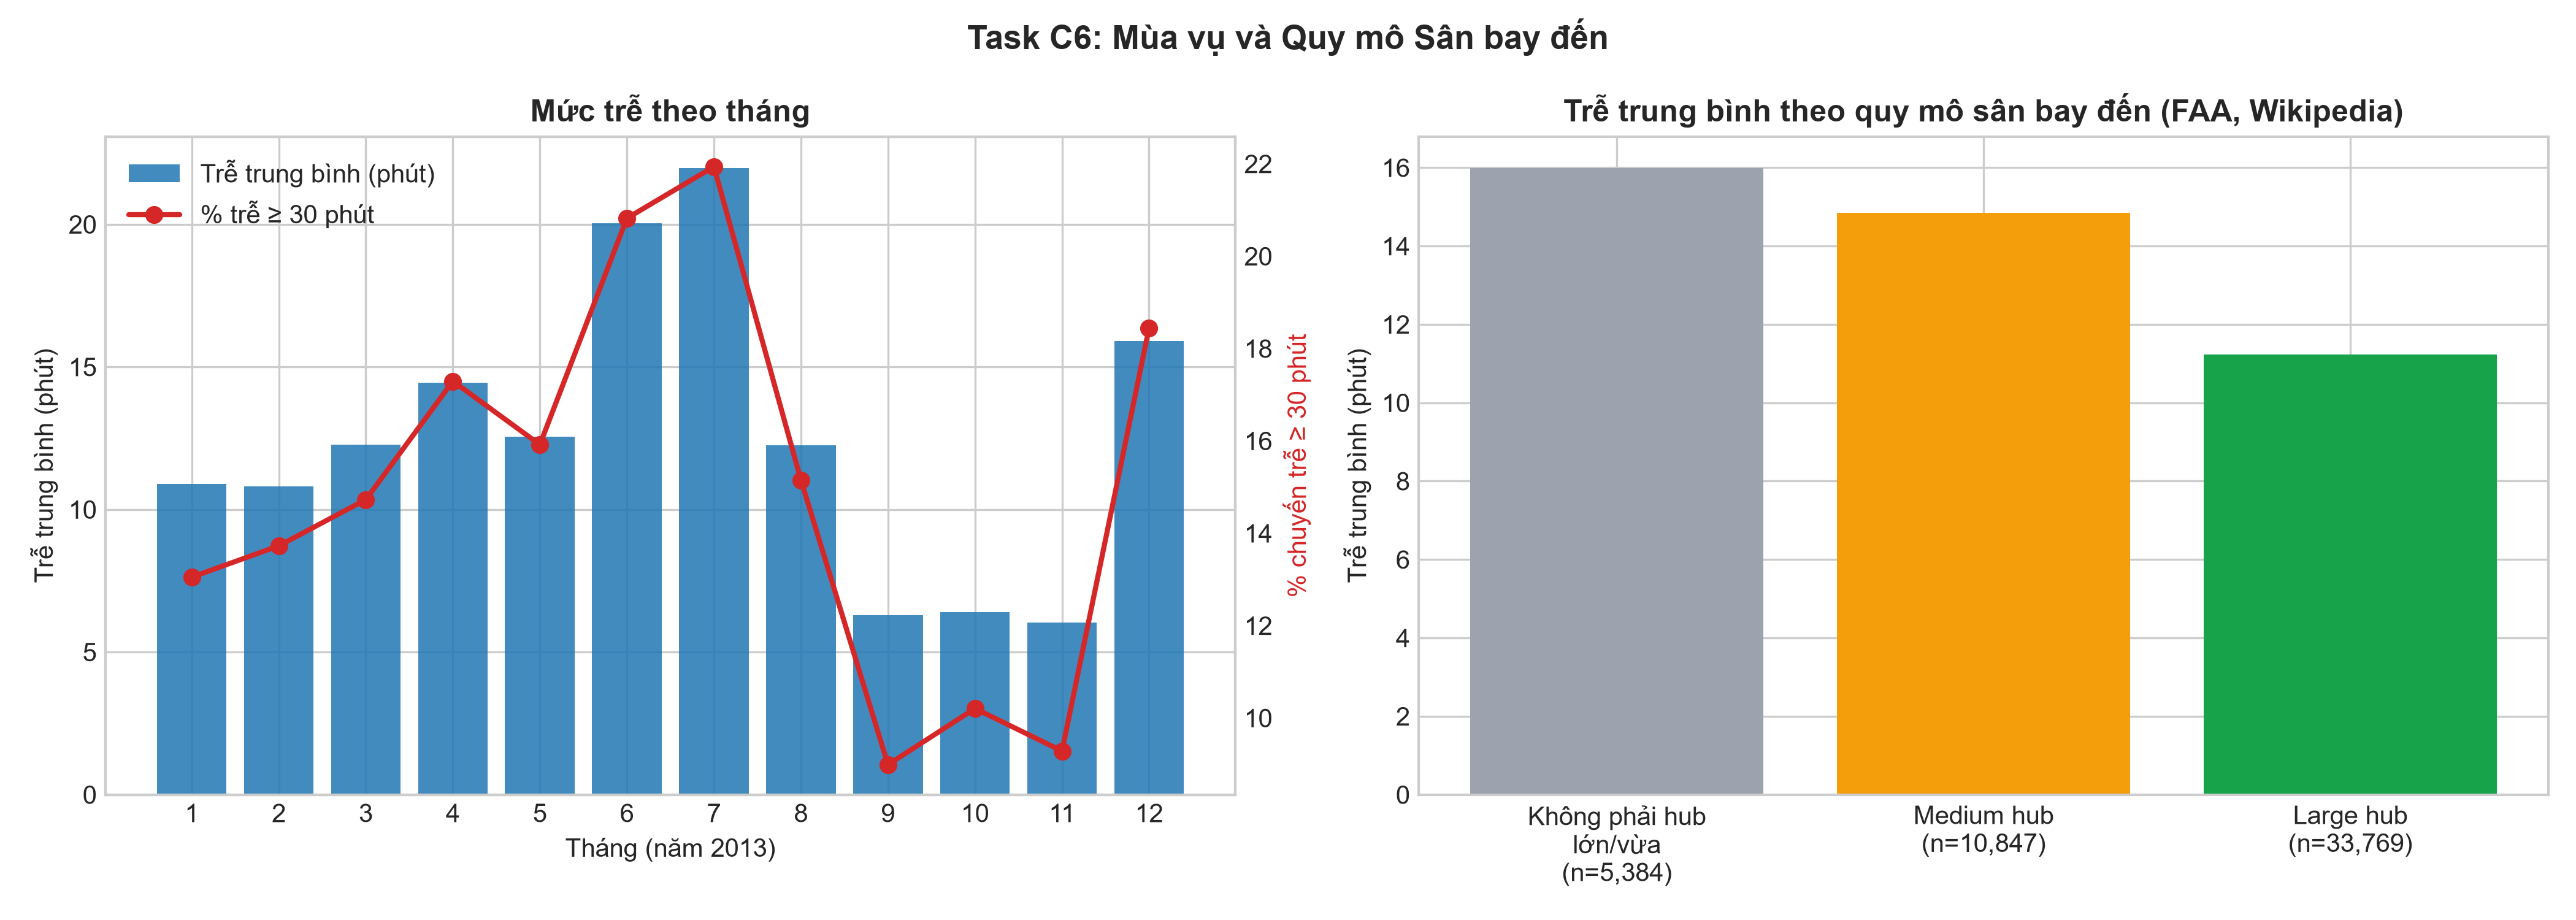

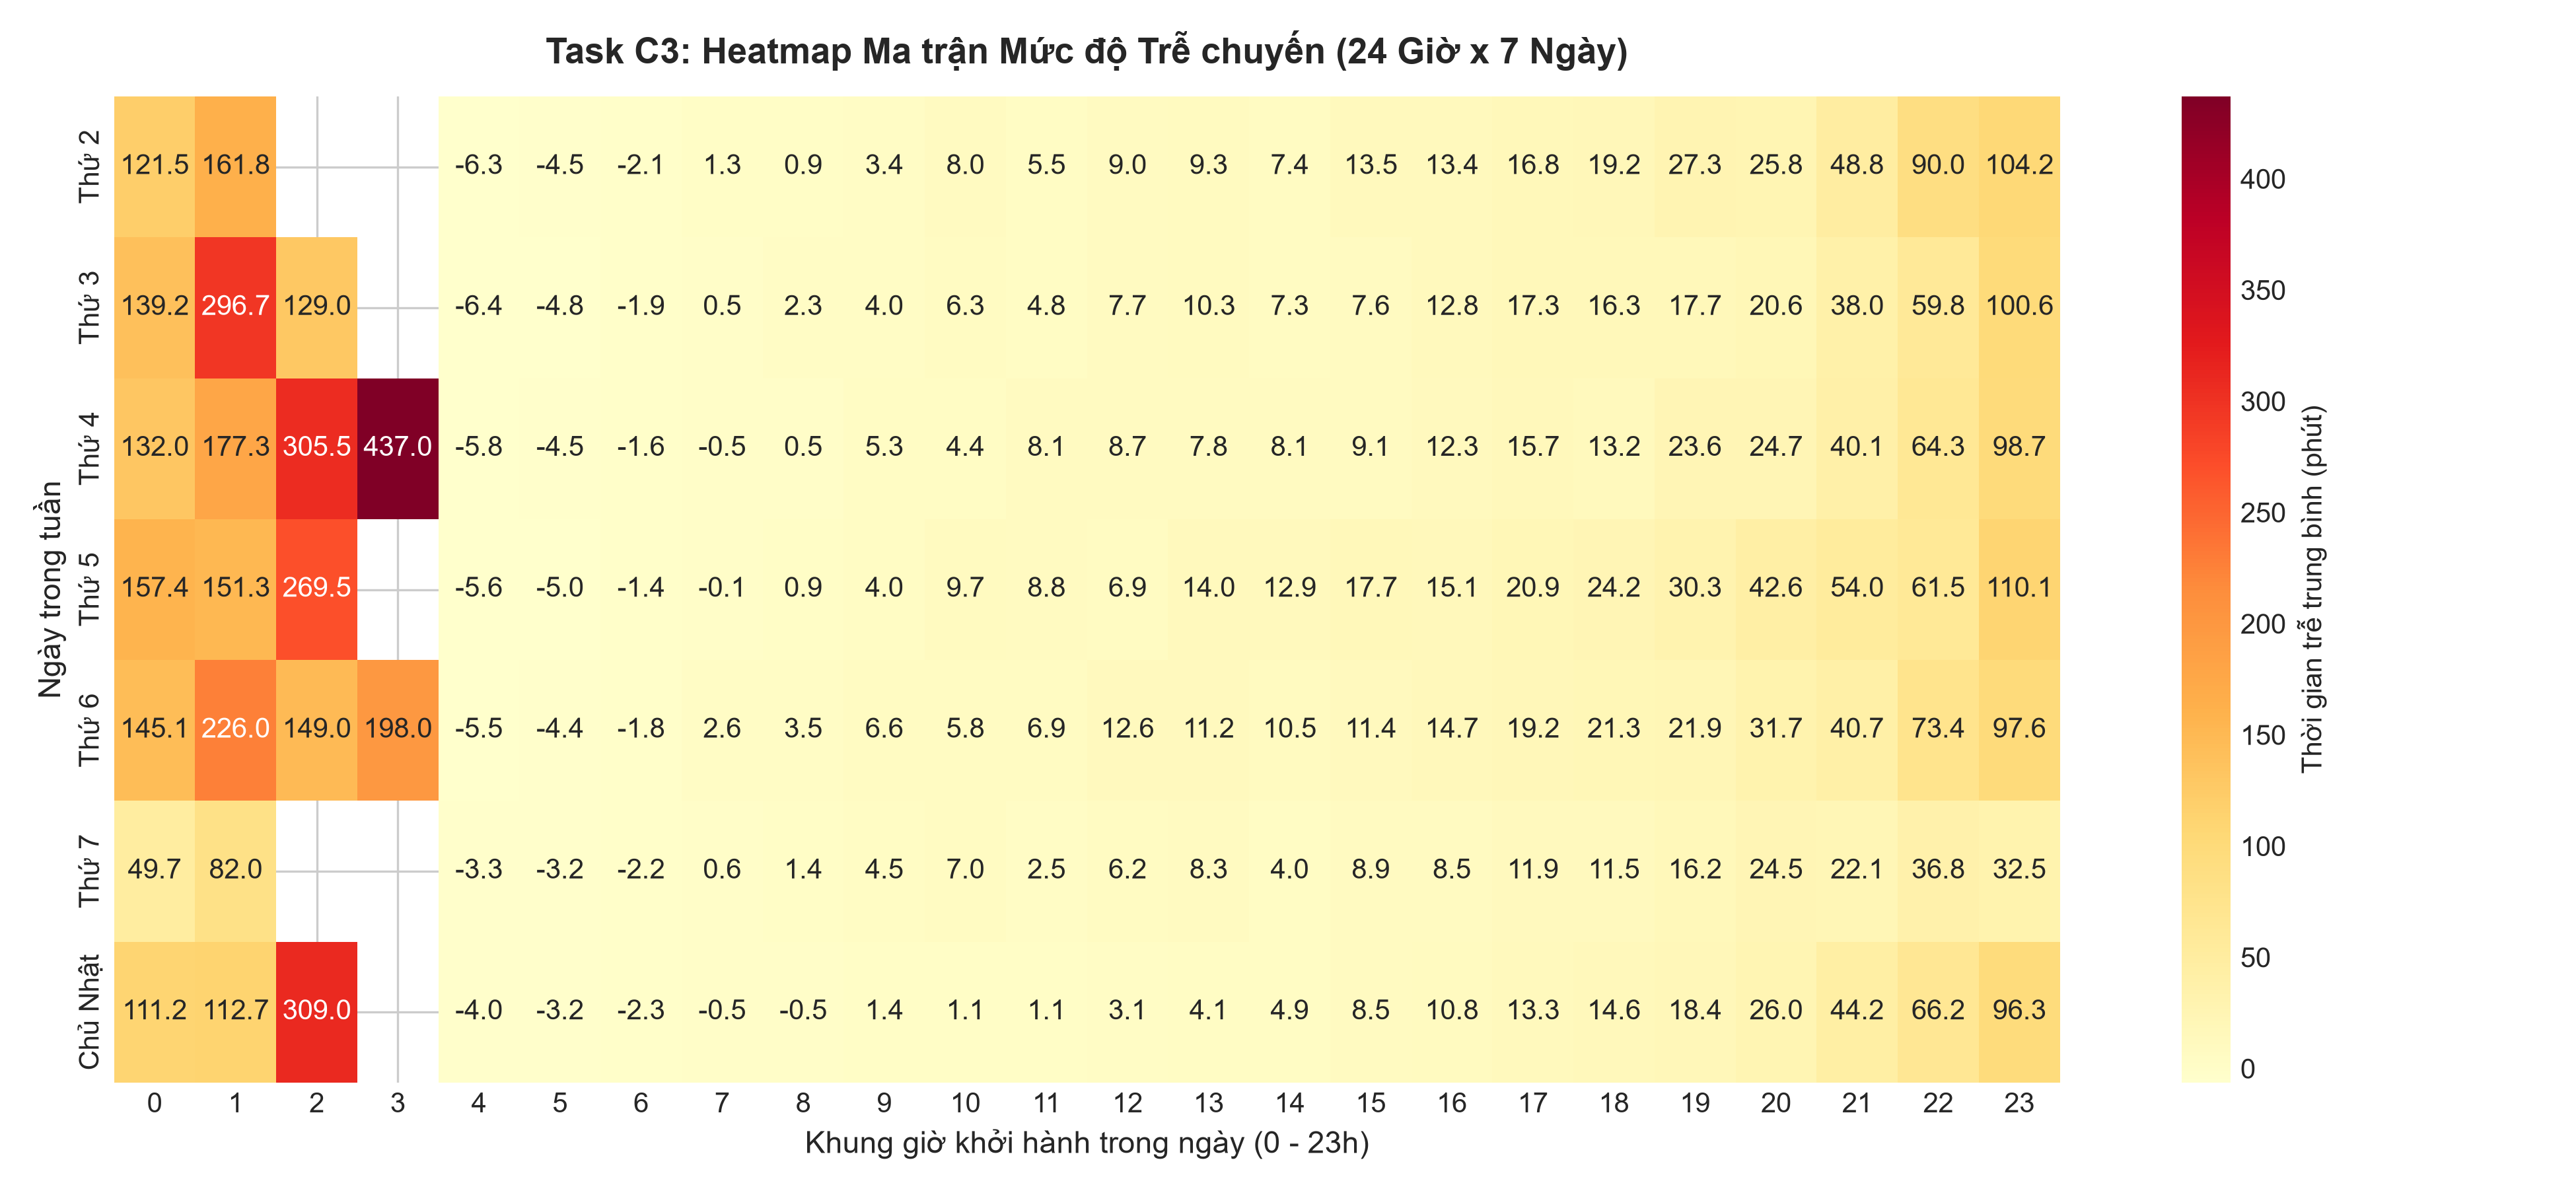

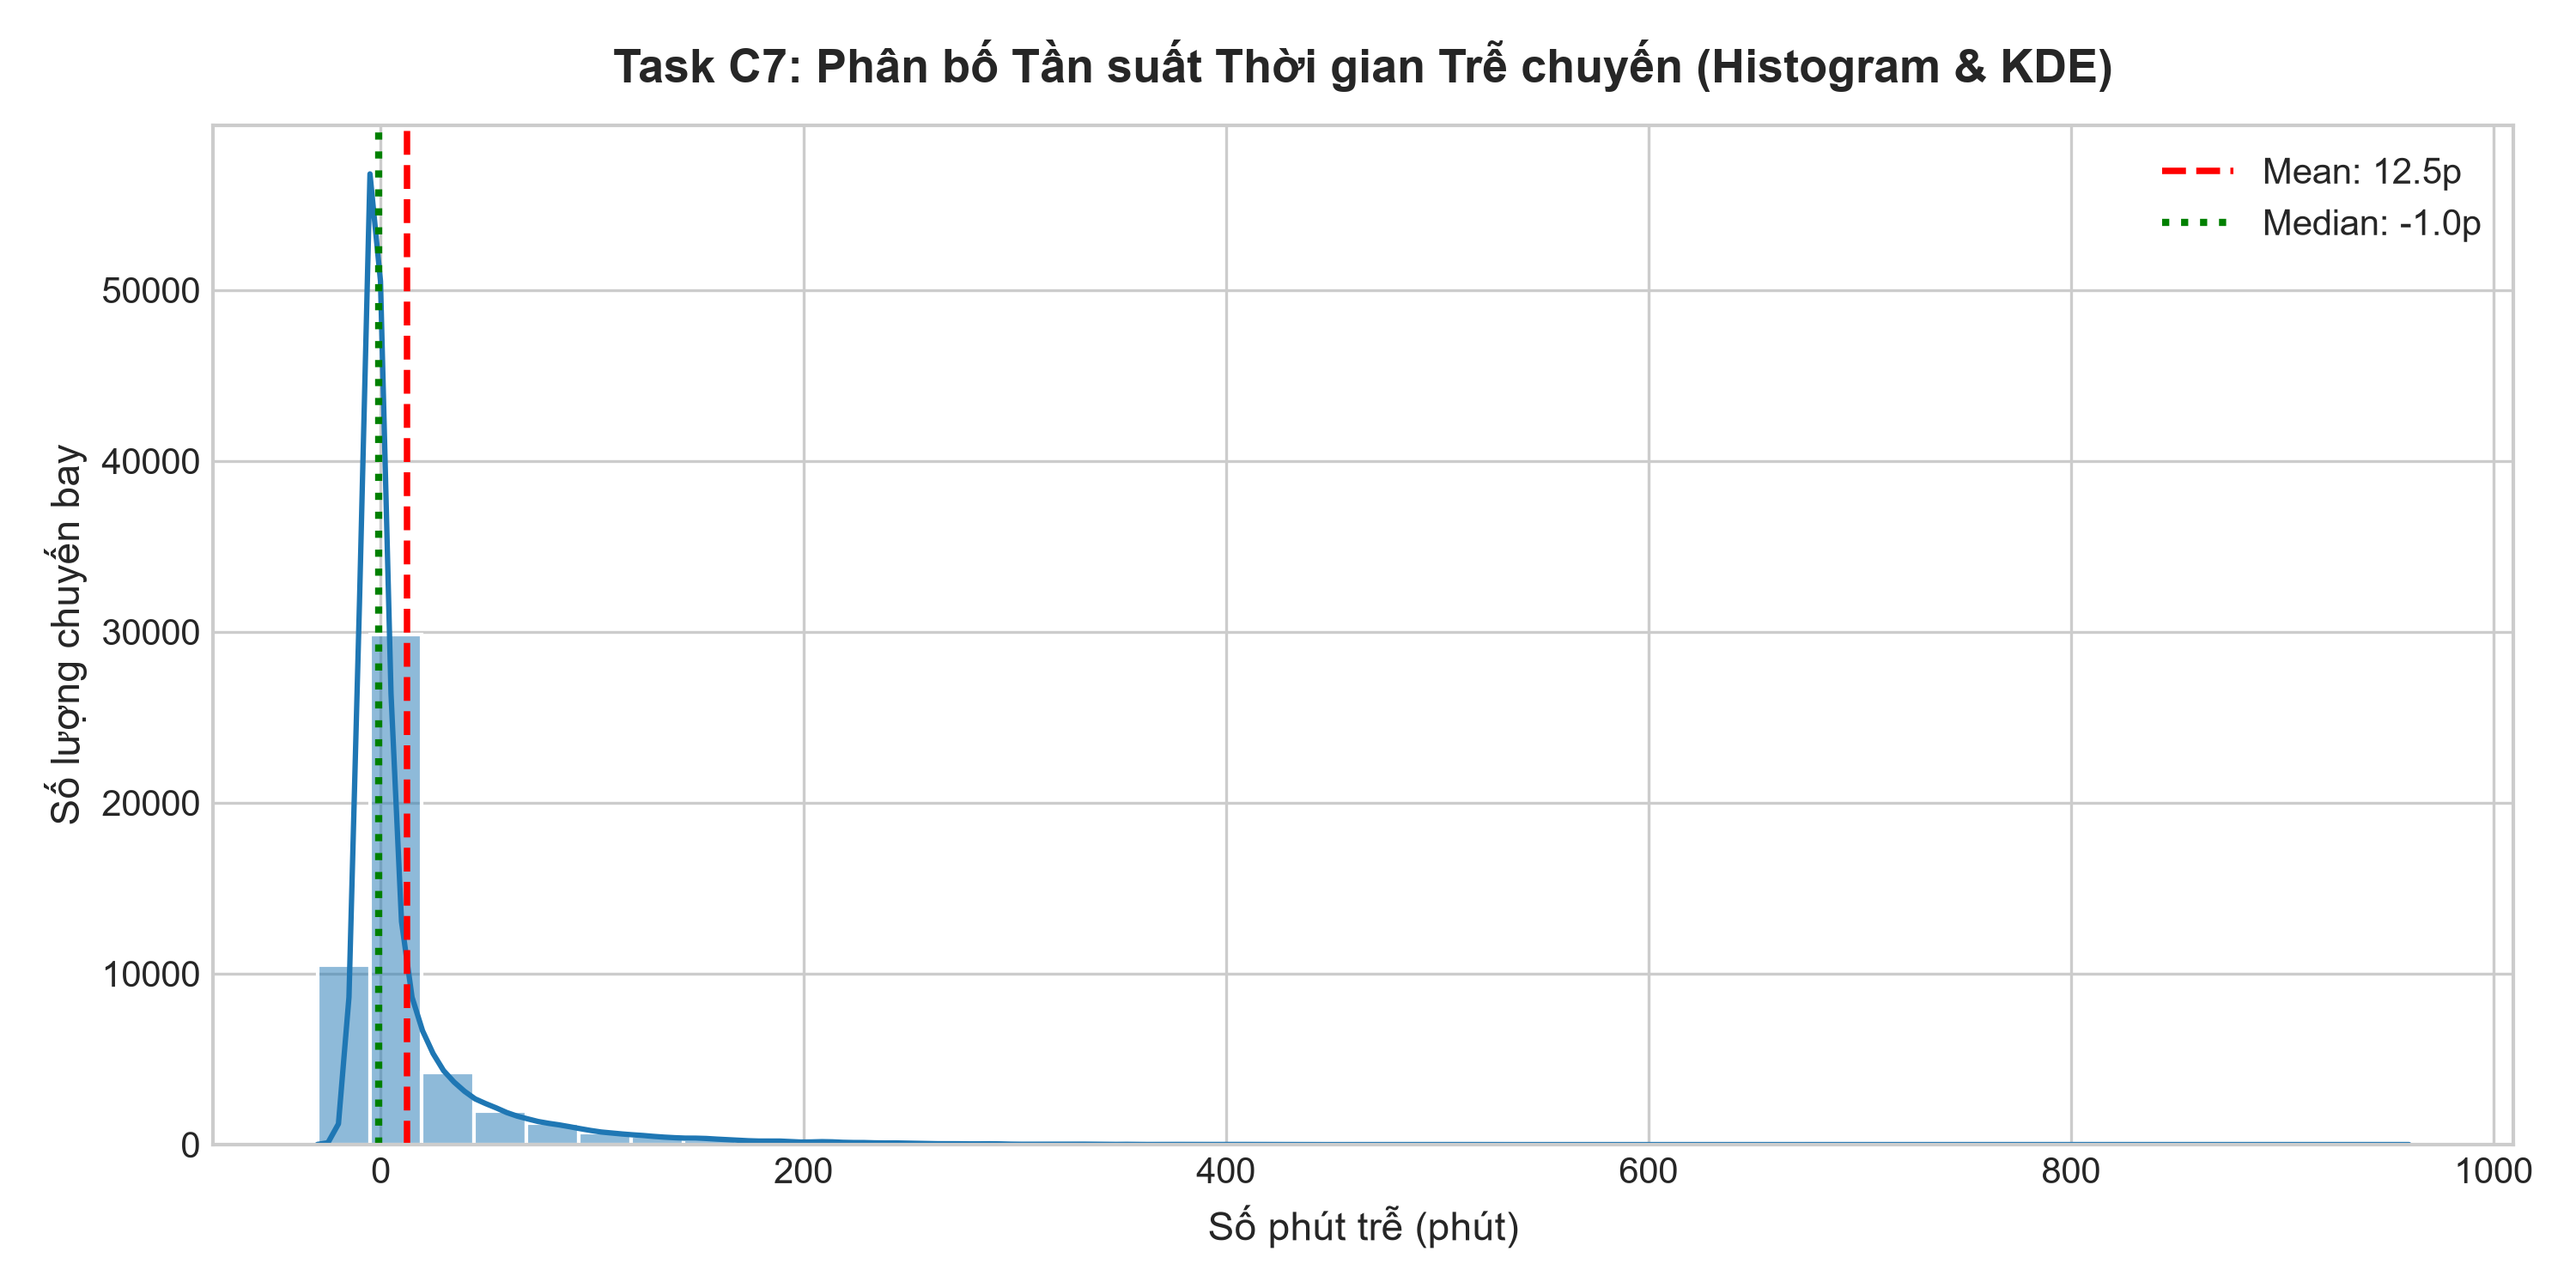

In [5]:
for name in ['task_c6_monthly_hub_delay.png', 'task_c3_heatmap_24x7.png', 'task_c7_delay_histogram.png']:
    display(Image(filename=os.path.join('docs/figures', name), width=900))

## 4. Giai đoạn D: Huấn luyện, Chọn siêu tham số & Đánh giá
- Chia tuần tự theo thời gian: Train 70% / Validation 15% / Test 15%.
- Mọi siêu tham số (alpha của Ridge/Lasso, độ sâu RF/XGBoost, có nén ngoại lai y_train hay không, ngưỡng phân loại) chọn trên **Validation**; Test chỉ dùng **một lần** để báo cáo.
- Bài toán phân loại trễ ≥ 30 phút: XGBClassifier có cân bằng lớp + hiệu chỉnh xác suất Isotonic.

In [6]:
from src.models.train_evaluate import train_and_compare_models

reg_df, cls_df = train_and_compare_models()
print('HỒI QUY - tập Test:')
display(reg_df)
print('PHÂN LOẠI TRỄ >= 30 PHÚT - tập Test:')
display(cls_df)
print('HIỆU CHỈNH XÁC SUẤT - tập Test:')
display(pd.read_csv('docs/figures/probability_calibration.csv'))

[Task D] Bắt đầu huấn luyện và đánh giá trên DỮ LIỆU THẬT...
[Task D1] Train 35,000 (01/01 - 13/09), Val 7,500, Test 7,500 (từ 06/11); 51 đặc trưng; biên IQR y_train = [-32.0, 40.0]


[Task D3] Linear Regression: nén y_train=có (Val MAE = 12.59)
[Task D3] Ridge (L2): alpha=0.1, nén y_train=có (Val MAE = 12.59)


[Task D3] Lasso (L1): alpha=0.001, nén y_train=có (Val MAE = 12.59)
[Task D5] Đang phân tích Overfitting theo độ sâu cây trên tập Validation...


[Task D5] max_depth tối ưu trên Val = 10 (Val MAE = 12.35)


[Task D4] Random Forest: max_depth=16, min_samples_leaf=5, nén y_train=có (Val MAE = 12.17)


[Task D4] XGBoost (reg:squarederror): max_depth=6, lr=0.03, số cây=573, nén y_train=có (Val MAE = 11.35)


... (4 outputs left out)

PHÂN LOẠI TRỄ >= 30 PHÚT - tập Test:


,Mô hình,Cấu hình (chọn trên Val),Accuracy (%),Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline 1 (Luôn đoán lớp đa số: không trễ),,85.5,0.0000,0.0000,0.0000,NaN,NaN
1,Baseline 2 (Persistence ≥ 30p),,82.8,0.3704,0.2693,0.3119,0.6767,0.3057
2,XGBoost (absolute error) - ngưỡng 30p,hồi quy rồi cắt ngưỡng,87.3,0.6744,0.2417,0.3559,0.7850,0.4743
3,XGBClassifier (ngưỡng 0.5),"max_depth=6, lr=0.03, số cây=155, scale_pos_we...",80.3,0.3794,0.5625,0.4532,0.7923,0.4752
4,XGBClassifier (ngưỡng 0.54 tối ưu F1 trên Val),"max_depth=6, lr=0.03, số cây=155, scale_pos_we...",82.2,0.4111,0.5294,0.4628,0.7923,0.4752


HIỆU CHỈNH XÁC SUẤT - tập Test:


,Xác suất,Trung bình dự báo,Tỷ lệ trễ thực tế,Brier score
0,Điểm thô XGBClassifier (scale_pos_weight),0.3379,0.1451,0.1449
1,Sau hiệu chỉnh Isotonic (fit trên Val),0.1216,0.1451,0.1011


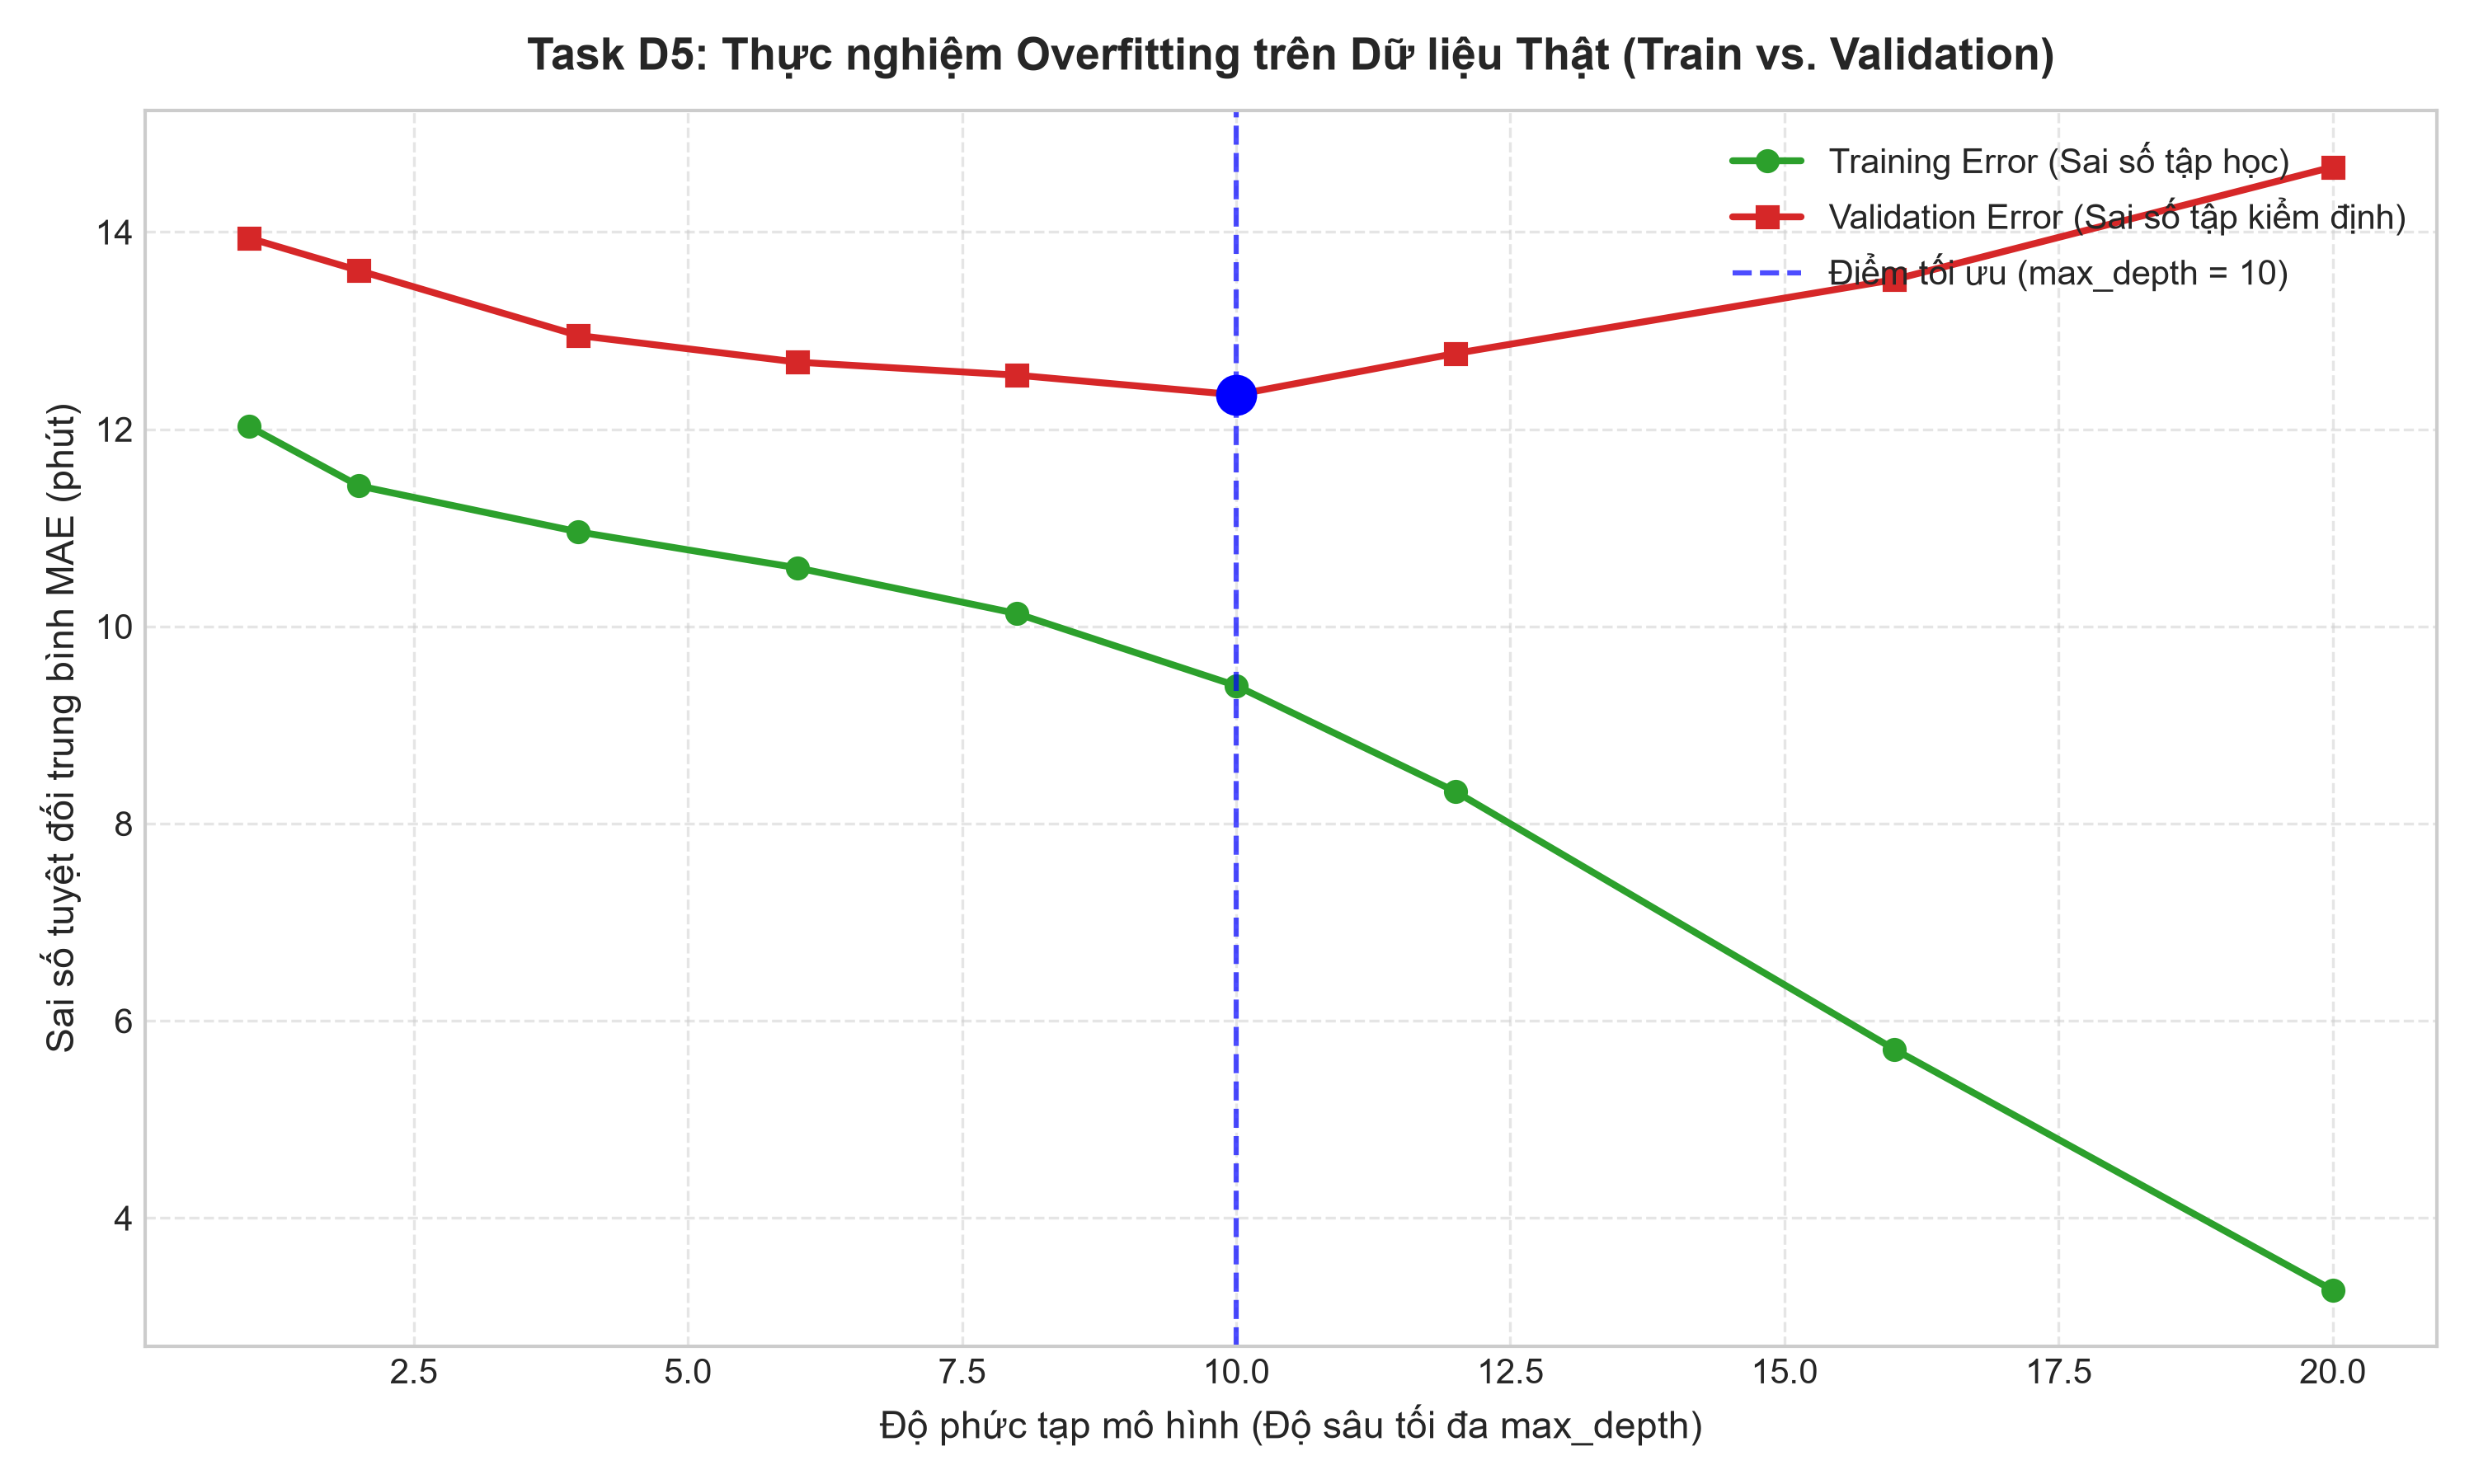

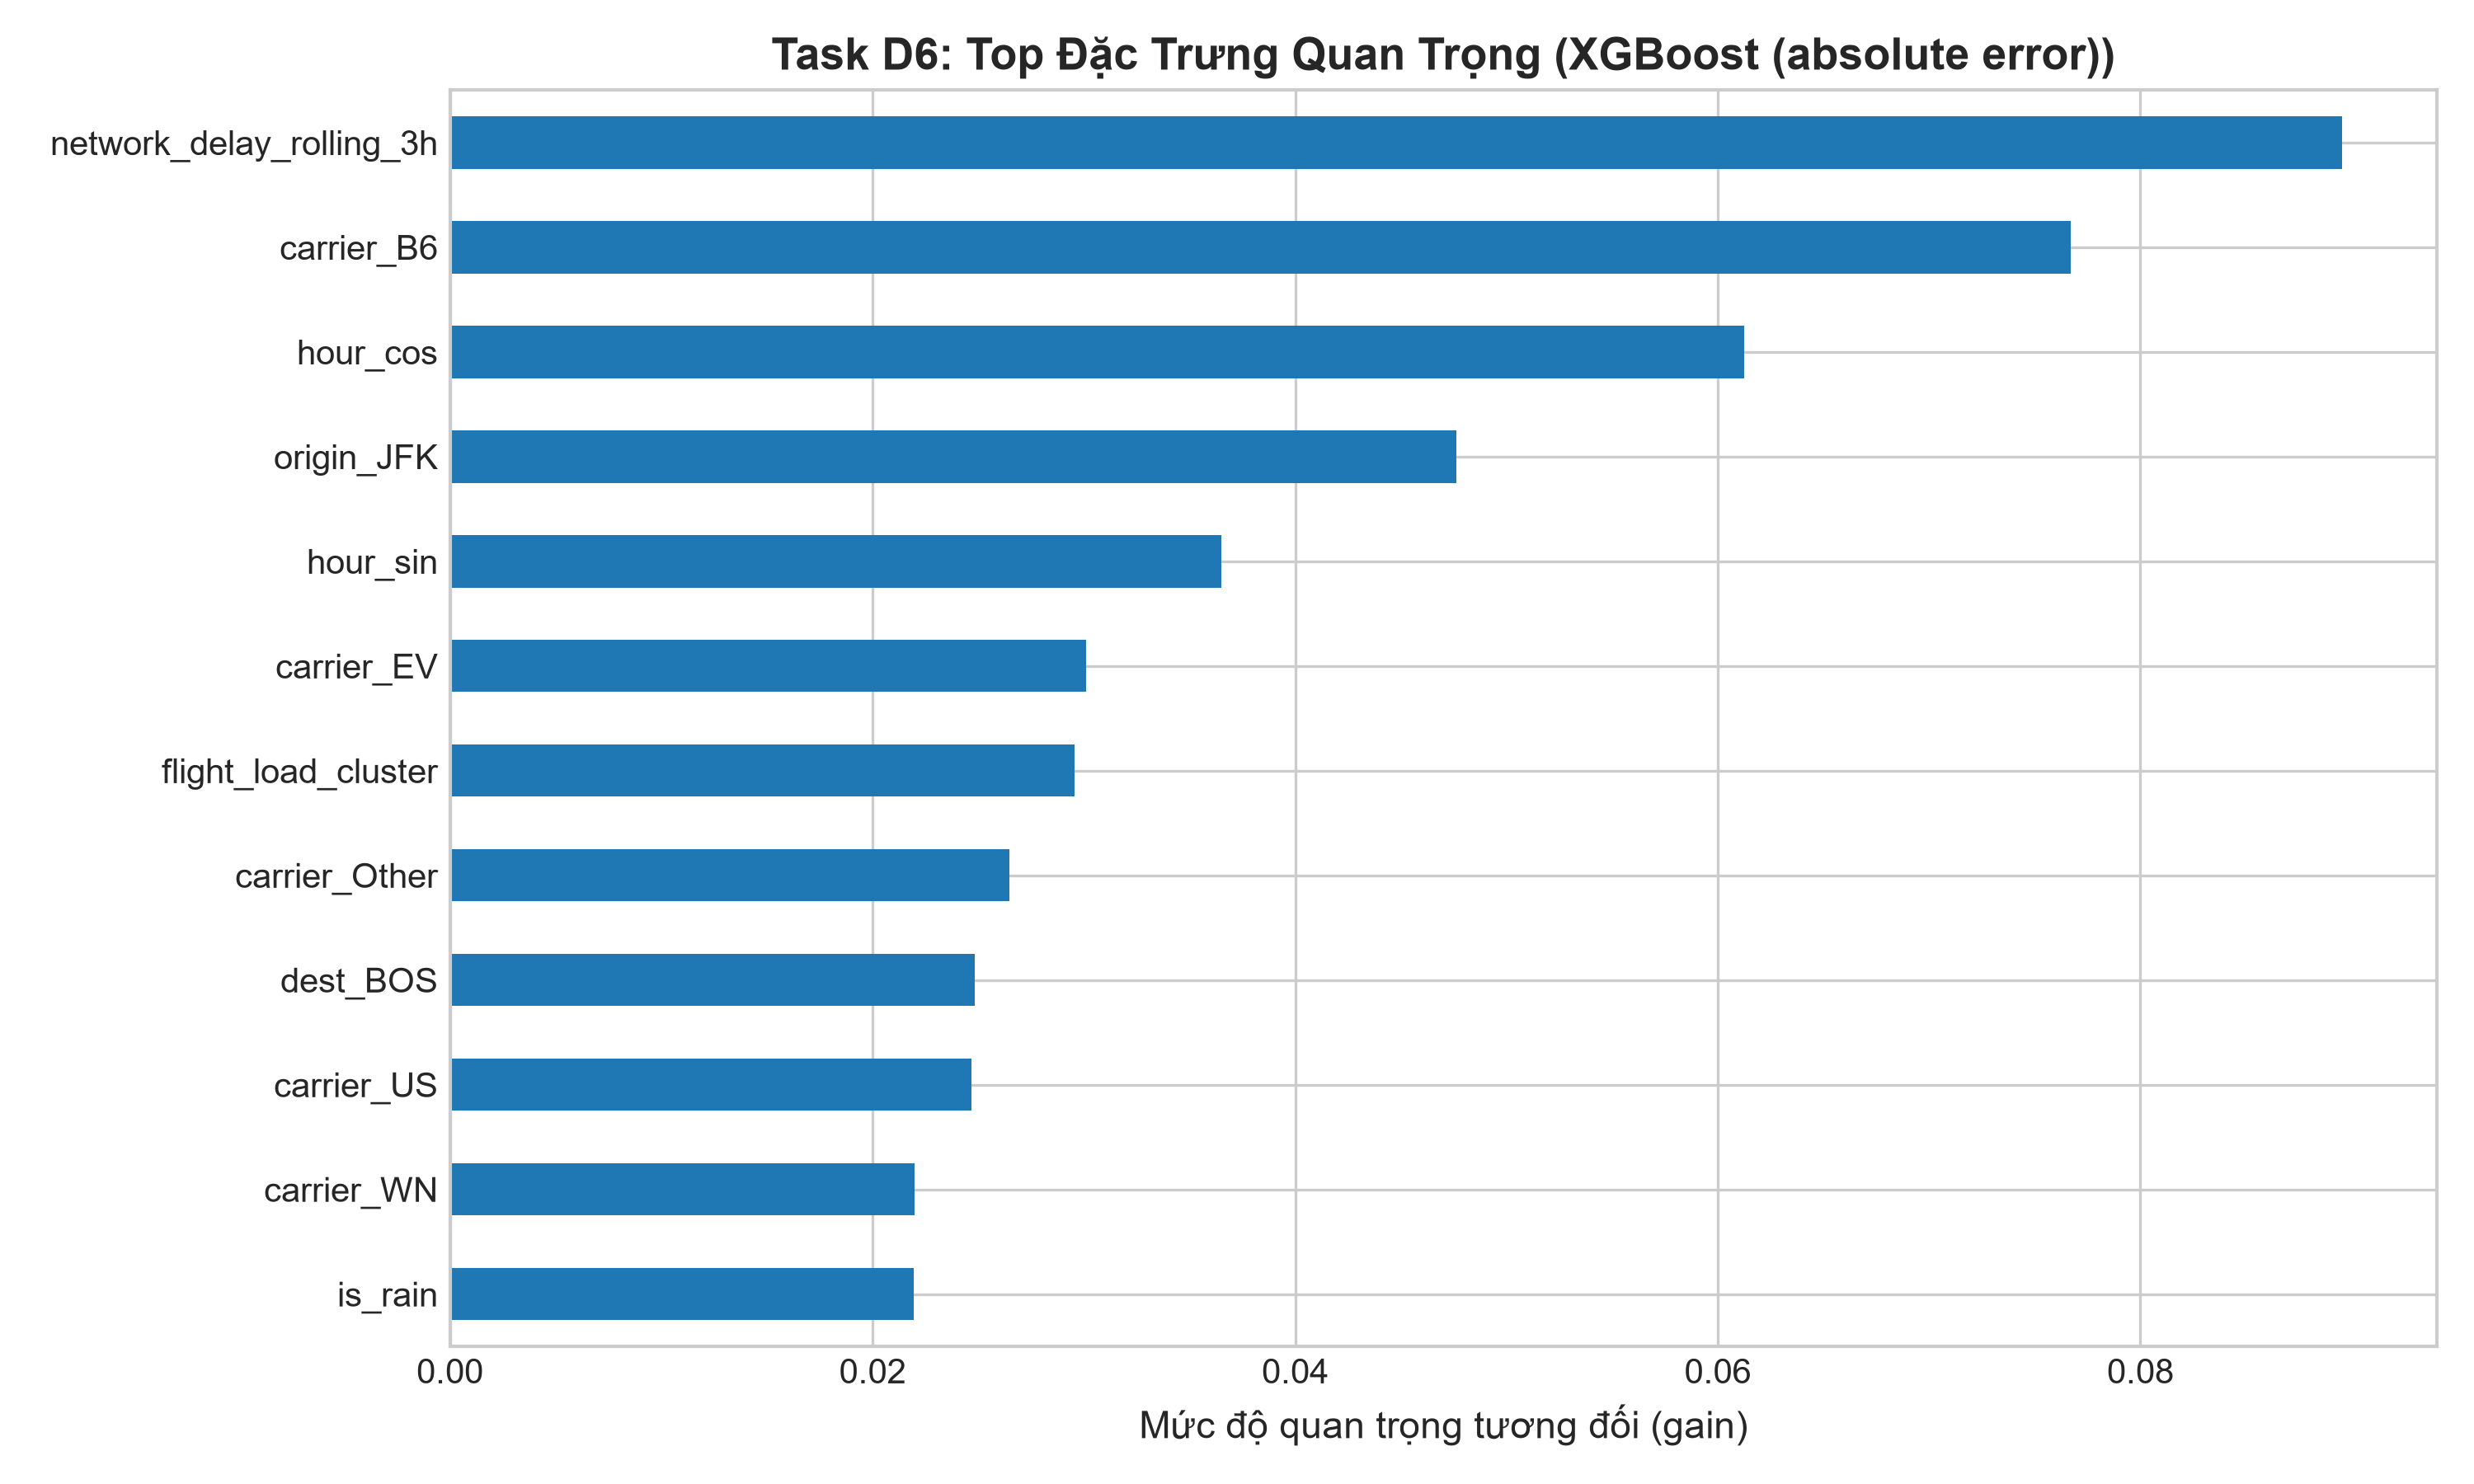

In [7]:
display(Image(filename='docs/figures/task_d5_overfitting_analysis.png', width=750))
display(Image(filename='docs/figures/task_d6_feature_importance.png', width=750))

## 5. Kết luận & Giới hạn
Ô dưới đây tóm tắt kết quả từ các bảng vừa tính.

In [8]:
best = reg_df.loc[reg_df['MAE (phút)'].idxmin()]
base = reg_df.iloc[0]
clf_best = cls_df.loc[cls_df['F1-Score'].idxmax()]
print(f"- Hồi quy: {best['Mô hình']} tốt nhất, MAE = {best['MAE (phút)']} phút, R2 = {best['R2 Score']} "
      f"(baseline hằng số: MAE = {base['MAE (phút)']}).")
print(f"- Phân loại trễ >= 30 phút: {clf_best['Mô hình']} đạt F1 = {clf_best['F1-Score']}, "
      f"ROC-AUC = {clf_best['ROC-AUC']}, PR-AUC = {clf_best['PR-AUC']}.")
print('- Giới hạn: dữ liệu chỉ 1 năm (2013) và 3 sân bay NYC; R2 thấp do đuôi phân phối trễ rất dài; '
      'tập Test (tháng 11-12) khác mùa với Train (tháng 1-9); số liệu sân bay từ Wikipedia sớm nhất là năm 2016.')

- Hồi quy: XGBoost (absolute error) tốt nhất, MAE = 14.76 phút, R2 = 0.2066 (baseline hằng số: MAE = 16.63).
- Phân loại trễ >= 30 phút: XGBClassifier (ngưỡng 0.54 tối ưu F1 trên Val) đạt F1 = 0.4628, ROC-AUC = 0.7923, PR-AUC = 0.4752.
- Giới hạn: dữ liệu chỉ 1 năm (2013) và 3 sân bay NYC; R2 thấp do đuôi phân phối trễ rất dài; tập Test (tháng 11-12) khác mùa với Train (tháng 1-9); số liệu sân bay từ Wikipedia sớm nhất là năm 2016.
